# F35 – Evidencia de aprendizaje 3. Optimización procesos de desarrollo
## Aplicación Web, Pipeline CI/CD con GitHub Actions y Despliegue en la Nube

* **Integrante:** Raúl Santiago Morales Henao  
* **Institución:** Institución Universitaria Digital de Antioquia (IU Digital)  
* **Asignatura:** Programación para Análisis de Datos (`PREICA2602B020048`)  
* **Docente:** Andrés Felipe Palacio  
* **Fecha:** 27 de noviembre de 2026  

> **Nota de reproducibilidad:** Todas las salidas e imágenes se encuentran pre-ejecutadas e incrustadas en este cuaderno. Para re-ejecutar las celdas de forma interactiva, clona el repositorio oficial y abre el archivo desde la raíz del proyecto (`git clone https://github.com/shenao356/mercadolibre-iphone17pm-shenao.git`).

### Enlaces Oficiales Verificados en Producción
* **Repositorio GitHub:** [https://github.com/shenao356/mercadolibre-iphone17pm-shenao](https://github.com/shenao356/mercadolibre-iphone17pm-shenao)  
* **Aplicación Web Desplegada (GitHub Pages):** [https://shenao356.github.io/mercadolibre-iphone17pm-shenao/](https://shenao356.github.io/mercadolibre-iphone17pm-shenao/)  
* **API JSON en Producción:** [https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/iphone17_data.json](https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/iphone17_data.json)  
* **Healthcheck Cloud:** [https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/health.json](https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/health.json)  
* **GitHub Actions:** [https://github.com/shenao356/mercadolibre-iphone17pm-shenao/actions](https://github.com/shenao356/mercadolibre-iphone17pm-shenao/actions)

---
## 1. Introducción y Continuidad de las Unidades 1, 2 y 3

Este cuaderno documenta y verifica en vivo la **Evidencia de Aprendizaje 3 (F35)** sobre el caso de estudio del **Apple iPhone 17 Pro Max en Mercado Libre Colombia** (48 publicaciones):
1. **Unidad 1 (EA1):** Análisis comparativo de **BeautifulSoup**, **Selenium** y **Scrapy**, extracción de datos y exportación a CSV/JSON.
2. **Unidad 2 (EA2):** Control de versiones con **Git y GitHub** por ramas, Pull Request #1, refinamiento del selector de precio real (`div.poly-price__current` frente al tachado `<s>`) y 6 pruebas unitarias.
3. **Unidad 3 (EA3):** Desarrollo de la **aplicación web WSGI + API REST (`app.py`)**, tablero interactivo v3.0.0 (`deploy_dashboard.py` con **Chart.js**), ampliación a **14 pruebas automatizadas**, configuración por **variables de entorno y contenedores (`Dockerfile`, `render.yaml`, `.env.example`)**, pipeline **CI/CD activo en `.github/workflows/ci_cd_pipeline.yml`** y despliegue continuo en **GitHub Pages**.

---
## 2. Paso 1: Auditoría del Control de Versiones y Ramificación (Git & GitHub)

Verificamos las 6 ramas del proyecto (`main`, `develop`, `rama-scraper`, `rama-pruebas`, `rama-automatizacion`, `rama-ea3-despliegue`) y el grafo de commits y fusiones `--no-ff`.

In [1]:
import subprocess

print("=== RAMAS DEL REPOSITORIO ===")
print(subprocess.check_output(["git", "branch", "-a", "-v"], text=True, encoding="utf-8"))

print("=== GRAFO DE COMMITS Y FUSIONES (EA1 -> EA2 -> EA3) ===")
print(subprocess.check_output(["git", "log", "--graph", "--oneline", "--decorate", "-n", "18"], text=True, encoding="utf-8"))

=== RAMAS DEL REPOSITORIO ===
* develop                            e64e919 [ahead 1] Actualizo las capturas de pantalla reales del despliegue y GitHub Actions
  main                               c783c49 Publico los cambios de la aplicacion web y el flujo de pruebas en main
  rama-automatizacion                c084ba7 Configuro la automatizacion del proyecto y el reporte web en la carpeta docs
  rama-ea3-despliegue                a7948ae Implemento aplicacion web WSGI, 8 pruebas de integracion, pipeline CI/CD y despliegue EA3
  rama-pruebas                       ad3cb4d Creo las pruebas automaticas para revisar que los precios y datos esten bien
  rama-scraper                       b5a57fb Agrego el script de python para hacer el web scraping en Mercado Libre
  remotes/origin/HEAD                -> origin/main
  remotes/origin/develop             a07d625 Actualizo los archivos web desplegados y la documentacion del README
  remotes/origin/main                c783c49 Publico los cambios

---
## 3. Paso 2: Integración Continua (CI) – Ejecución de las 14 Pruebas Automatizadas

La compuerta de calidad (*Quality Gate*) ejecuta **6 pruebas unitarias del scraper y datasets (`tests/test_scraper.py`)** más **8 pruebas de integración HTTP sobre el servidor WSGI y el generador de despliegue (`tests/test_webapp.py`)**.

In [2]:
import unittest

loader = unittest.TestLoader()
suite = loader.discover(start_dir="tests", pattern="test_*.py")
runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)

print(f"\n[CI QUALITY GATE] Pruebas ejecutadas: {result.testsRun} | Exitosas: {result.testsRun - len(result.failures) - len(result.errors)} | Fallidas: {len(result.failures)}")

test_01_html_extraction_count (test_scraper.TestMercadoLibreScraperPipeline)
Verifica que el parser BeautifulSoup extraiga exactamente los 3 ítems del DOM de prueba. ... ok
test_02_current_price_vs_crossed_out_price (test_scraper.TestMercadoLibreScraperPipeline)
Valida que se extraiga el precio actual de venta (5.685.686) y NO el precio anterior tachado (6.999.000). ... ok
test_03_storage_capacity_normalization (test_scraper.TestMercadoLibreScraperPipeline)
Comprueba la detección mediante expresiones regulares de la capacidad (256GB, 512GB, 1TB). ... ok
test_04_shipping_and_wid_url_preservation (test_scraper.TestMercadoLibreScraperPipeline)
Verifica la normalización del envío gratis y que se conserve el identificador de oferta wid= en la URL. ... ok
test_05_production_csv_dataset_integrity (test_scraper.TestMercadoLibreScraperPipeline)
Audita la integridad del dataset de producción CSV (48 artículos de iPhone 17 Pro Max). ... ok
test_06_production_json_dataset_integrity (test_scraper.T

---
## 4. Paso 3: Prueba en Vivo de la Aplicación Web WSGI y API REST (`app.py`)

Iniciamos una instancia real del servidor WSGI en un puerto efímero local y consumimos `/api/health`, `/api/metrics` y `/api/products?descuento=true&sort=asc`.

In [3]:
import json
import threading
import requests
from app import create_server

httpd, port = create_server("127.0.0.1", 0)
server_thread = threading.Thread(target=httpd.serve_forever, daemon=True)
server_thread.start()

try:
    health = requests.get(f"http://127.0.0.1:{port}/api/health", timeout=5).json()
    metrics = requests.get(f"http://127.0.0.1:{port}/api/metrics", timeout=5).json()
    discounts = requests.get(f"http://127.0.0.1:{port}/api/products?descuento=true&sort=asc", timeout=5).json()

    print("=== 1. ENDPOINT GET /api/health ===")
    print(json.dumps(health, indent=2, ensure_ascii=False))

    print("\n=== 2. ENDPOINT GET /api/metrics (Resumen) ===")
    summary = {k: v for k, v in metrics["metrics"].items() if k != "capacity_summary"}
    print(json.dumps(summary, indent=2, ensure_ascii=False))

    print(f"\n=== 3. ENDPOINT GET /api/products?descuento=true&sort=asc ({discounts['total_matched']} ofertas) ===")
    for p in discounts["data"]:
        print(f"  #{p['id']} | {p['precio_formateado']} ({p['descuento']}, antes {p['precio_anterior']}) | {p['capacidad']} | {p['titulo'][:55]}")
finally:
    httpd.shutdown()
    httpd.server_close()

=== 1. ENDPOINT GET /api/health ===
{
  "status": "ok",
  "service": "mercadolibre-iphone17pm-web",
  "version": "3.0.0",
  "environment": "production",
  "deploy_target": "GitHub Pages",
  "records_loaded": 48,
  "timestamp_utc": "2026-11-28 02:35 UTC"
}

=== 2. ENDPOINT GET /api/metrics (Resumen) ===
{
  "mean_price": 4776155.96,
  "median_price": 4600000.0,
  "min_price": 2667777,
  "max_price": 7990000,
  "std_price": 1129409.97,
  "range_price": 5322223,
  "cv_percent": 23.65,
  "discount_count": 3,
  "price_distribution": {
    "labels": [
      "< 3.5M",
      "3.5M - 4.5M",
      "4.5M - 5.5M",
      "5.5M - 6.5M",
      "> 6.5M"
    ],
    "counts": [
      2,
      20,
      15,
      7,
      4
    ]
  }
}

=== 3. ENDPOINT GET /api/products?descuento=true&sort=asc (3 ofertas) ===
  #7 | $ 4.329.639 (21% OFF, antes $ 5.480.559) | 256GB | Smartphone Esim Azul Apple iPhone 17 Pro Max 256 Gb
  #1 | $ 5.685.686 (18% OFF, antes $ 6.999.000) | 256GB | Apple iPhone 17 Pro Max (256 G

---
## 5. Paso 4: Inspección del Pipeline CI/CD Activo en GitHub Actions

Validamos la definición YAML activa en `.github/workflows/ci_cd_pipeline.yml` con sus tres etapas encadenadas (`lint-and-syntax`, `ci-automated-tests` y `cd-build-and-verify`).

In [4]:
with open(".github/workflows/ci_cd_pipeline.yml", "r", encoding="utf-8") as f:
    pipeline_yaml = f.read()

print(f"Workflow activo verificado: .github/workflows/ci_cd_pipeline.yml ({len(pipeline_yaml.splitlines())} líneas).")
print("-" * 75)
print(pipeline_yaml[:1650])
print("... [Definición completa en .github/workflows/ci_cd_pipeline.yml] ...")

Workflow activo verificado: .github/workflows/ci_cd_pipeline.yml (154 líneas).
---------------------------------------------------------------------------
# =============================================================================
# PIPELINE CI/CD CON GITHUB ACTIONS - EVIDENCIA DE APRENDIZAJE 3 (EA3)
# Flujo activo de integracion continua, pruebas y verificacion de despliegue
# =============================================================================
name: Pipeline CI/CD - App Web iPhone 17 Pro Max

on:
  push:
    branches:
      - main
      - develop
      - rama-ea3-despliegue
  pull_request:
    branches:
      - main
      - develop
  schedule:
    - cron: '0 6 * * 1'
  workflow_dispatch:
    inputs:
      environment:
        description: 'Entorno destino del build (production / staging)'
        required: false
        default: 'production'
        type: choice
        options:
          - production
          - staging

permissions:
  contents: read

concurrency:
  gro

---
## 6. Paso 5: Verificación en Vivo del Despliegue en la Nube y GitHub Actions

Consultamos directamente el servicio productivo en **GitHub Pages** y la API pública de **GitHub Actions** para confirmar el estado `200 OK`, la versión `3.0.0`, la trazabilidad del commit `e363345` y las ejecuciones exitosas de ambos workflows.

HTTP Status Aplicación Web GitHub Pages: 200 OK
=== ENDPOINT CLOUD /api/health.json ===
{
  "status": "ok",
  "service": "mercadolibre-iphone17pm-web",
  "version": "3.0.0",
  "environment": "production",
  "deploy_target": "GitHub Pages",
  "records_loaded": 48,
  "build_commit_sha": "e363345",
  "built_at_utc": "2026-11-28 02:17 UTC"
}

=== ÚLTIMAS EJECUCIONES VERIFICADAS EN GITHUB ACTIONS ===
  Run #3  | Pipeline CI/CD - App Web iPhone 17 Pro Max | rama=develop | estado=success | commit=a07d625
  Run #2  | Pipeline CI/CD - App Web iPhone 17 Pro Max | rama=main | estado=success | commit=c783c49
  Run #13 | pages build and deployment | rama=main | estado=success | commit=c783c49
  Run #1  | Pipeline CI/CD - App Web iPhone 17 Pro Max | rama=develop | estado=success | commit=e363345
  Run #12 | pages build and deployment | rama=main | estado=success | commit=0c4b56b


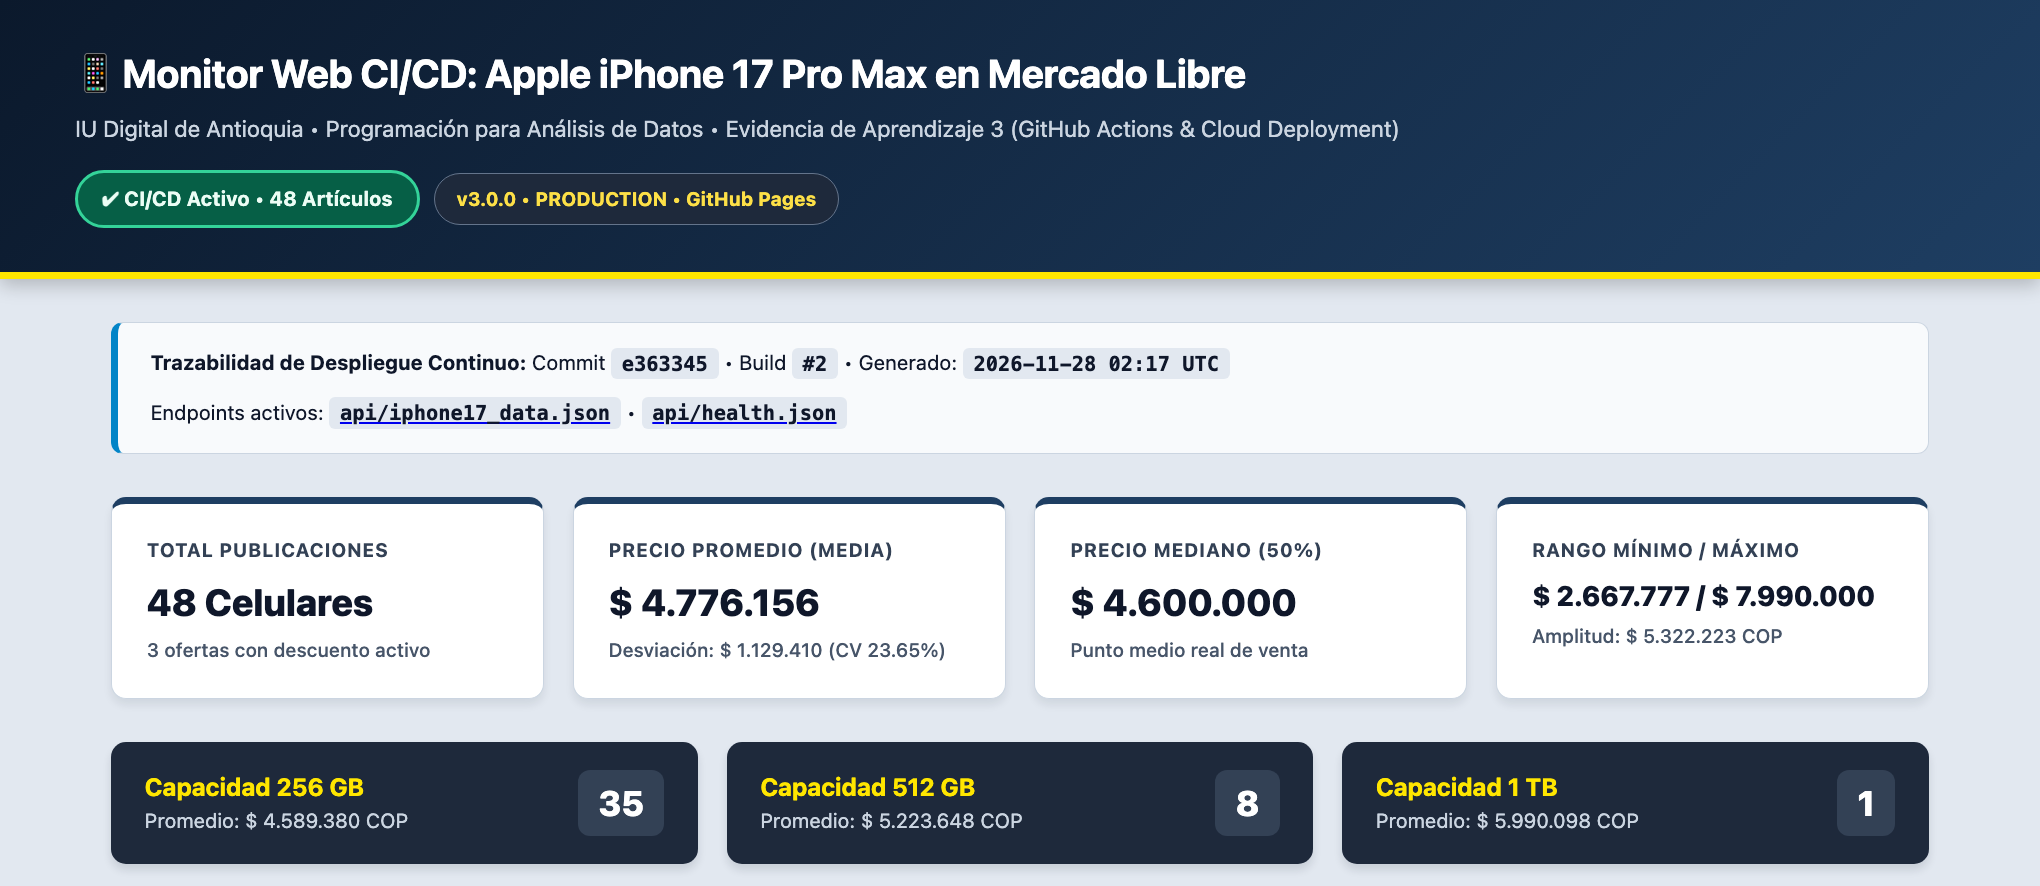

In [5]:
import json
import requests
from IPython.display import Image, display

url_app = "https://shenao356.github.io/mercadolibre-iphone17pm-shenao/"
url_health = url_app + "api/health.json"
url_runs = "https://api.github.com/repos/shenao356/mercadolibre-iphone17pm-shenao/actions/runs?per_page=5"

resp_app = requests.get(url_app, timeout=10)
resp_health = requests.get(url_health, timeout=10).json()
runs = requests.get(url_runs, timeout=10).json().get("workflow_runs", [])

print(f"HTTP Status Aplicación Web GitHub Pages: {resp_app.status_code} OK")
print("=== ENDPOINT CLOUD /api/health.json ===")
print(json.dumps(resp_health, indent=2, ensure_ascii=False))

print("\n=== ÚLTIMAS EJECUCIONES VERIFICADAS EN GITHUB ACTIONS ===")
for r in runs:
    print(f"  Run #{r['run_number']:<2} | {r['name']} | rama={r['head_branch']} | estado={r['conclusion']} | commit={r['head_sha'][:7]}")

display(Image(filename="docs/screenshots/01_webapp_produccion_superior.png"))

---
## 7. Evidencia Visual Complementaria: Gráficas en Producción y Pipeline CI/CD

Mostramos las capturas reales de las gráficas interactivas Chart.js en producción y las ejecuciones en verde en GitHub Actions.

Captura 2: Gráficas Chart.js y Catálogo Interactivo en Producción (GitHub Pages)


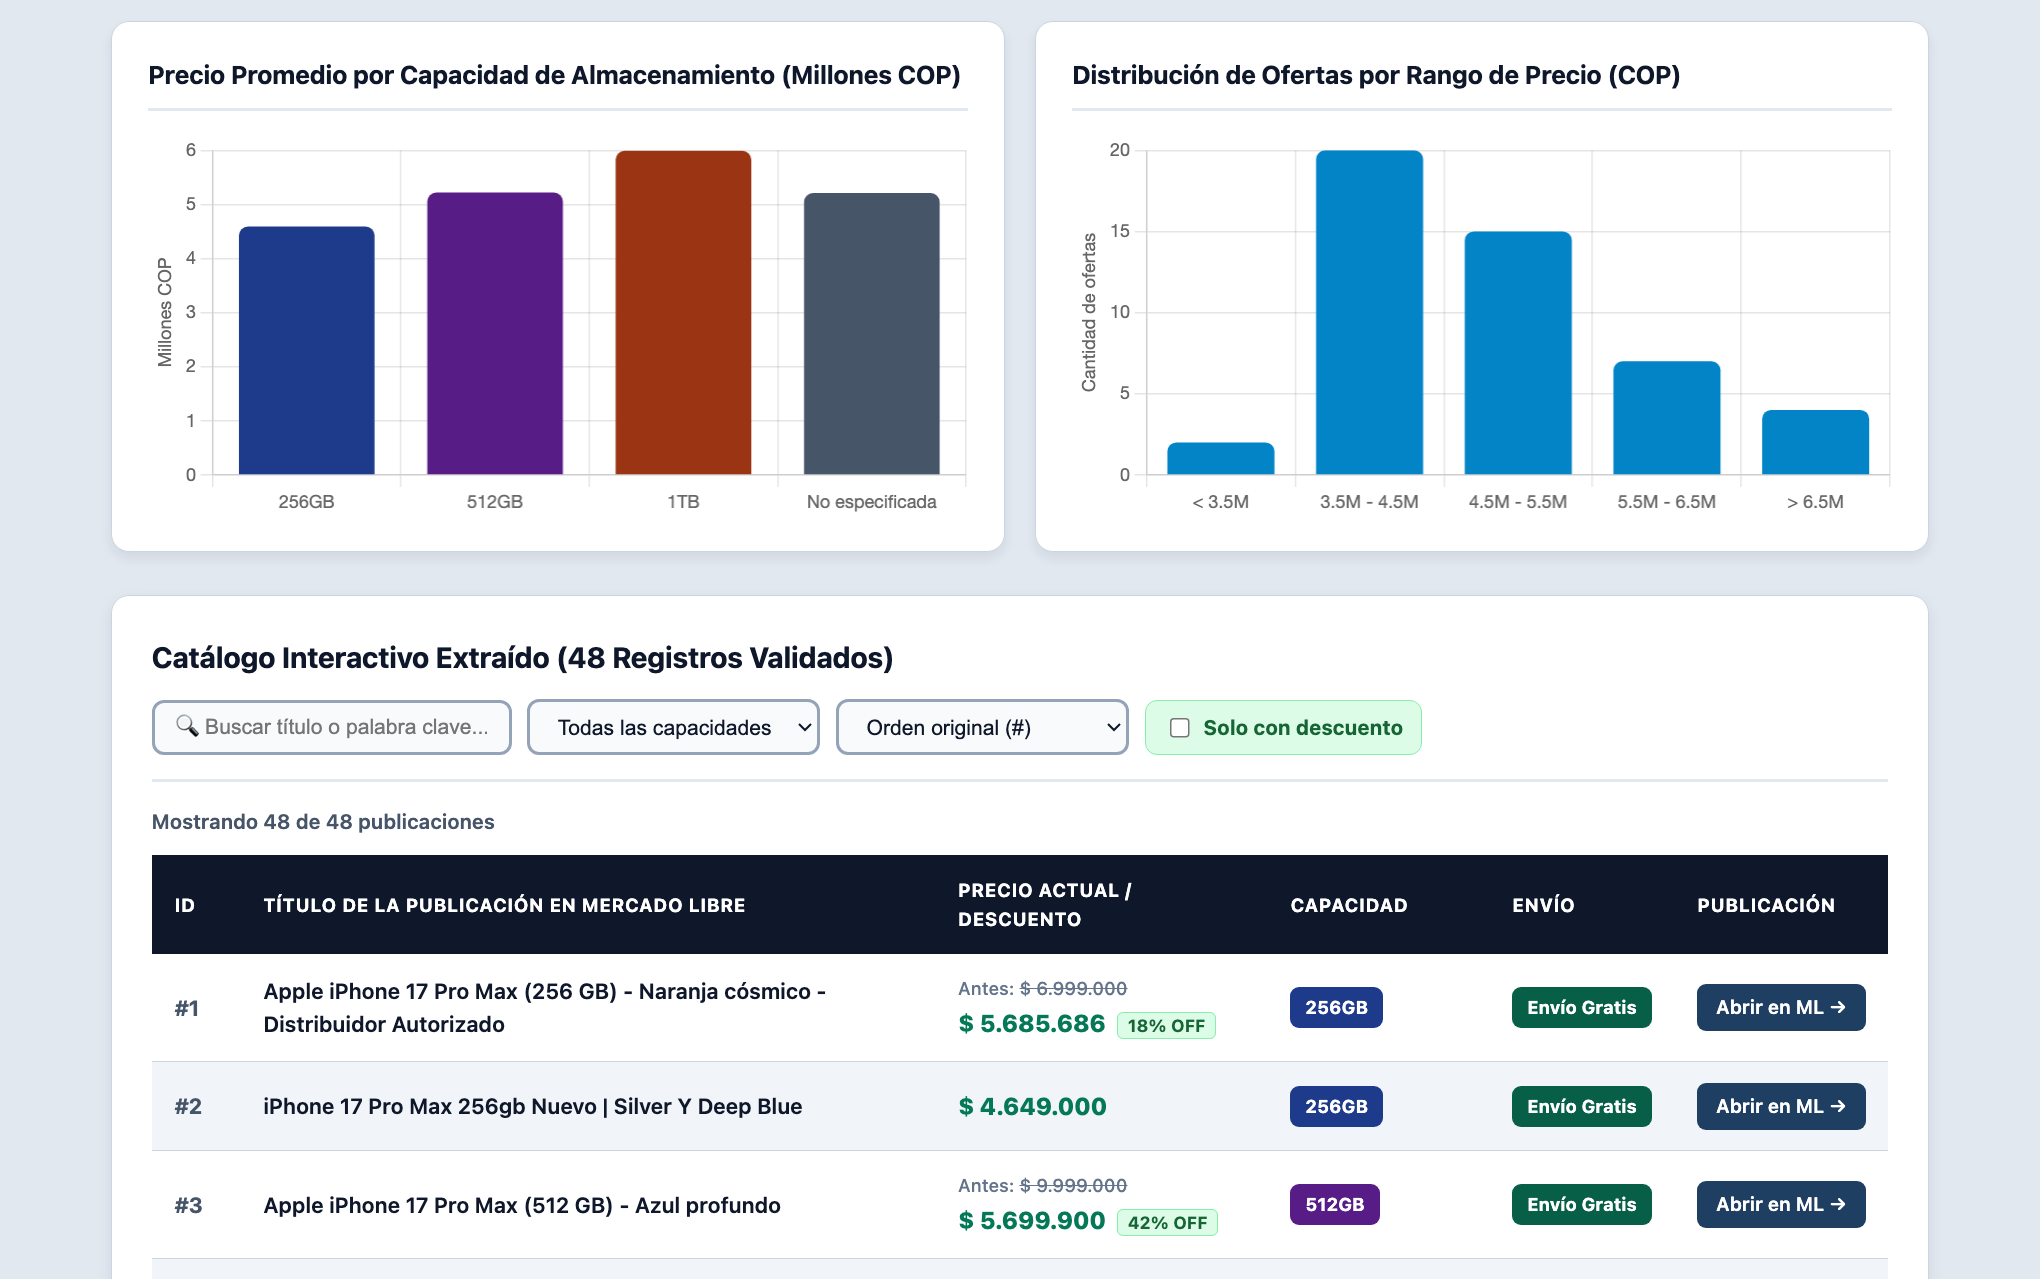

In [6]:
from IPython.display import Image, display

print("Captura 2: Gráficas Chart.js y Catálogo Interactivo en Producción (GitHub Pages)")
display(Image(filename="docs/screenshots/02_webapp_graficas_catalogo.png"))

Captura 3: Ejecución exitosa del pipeline CI/CD de 3 etapas en GitHub Actions (#2 en main)


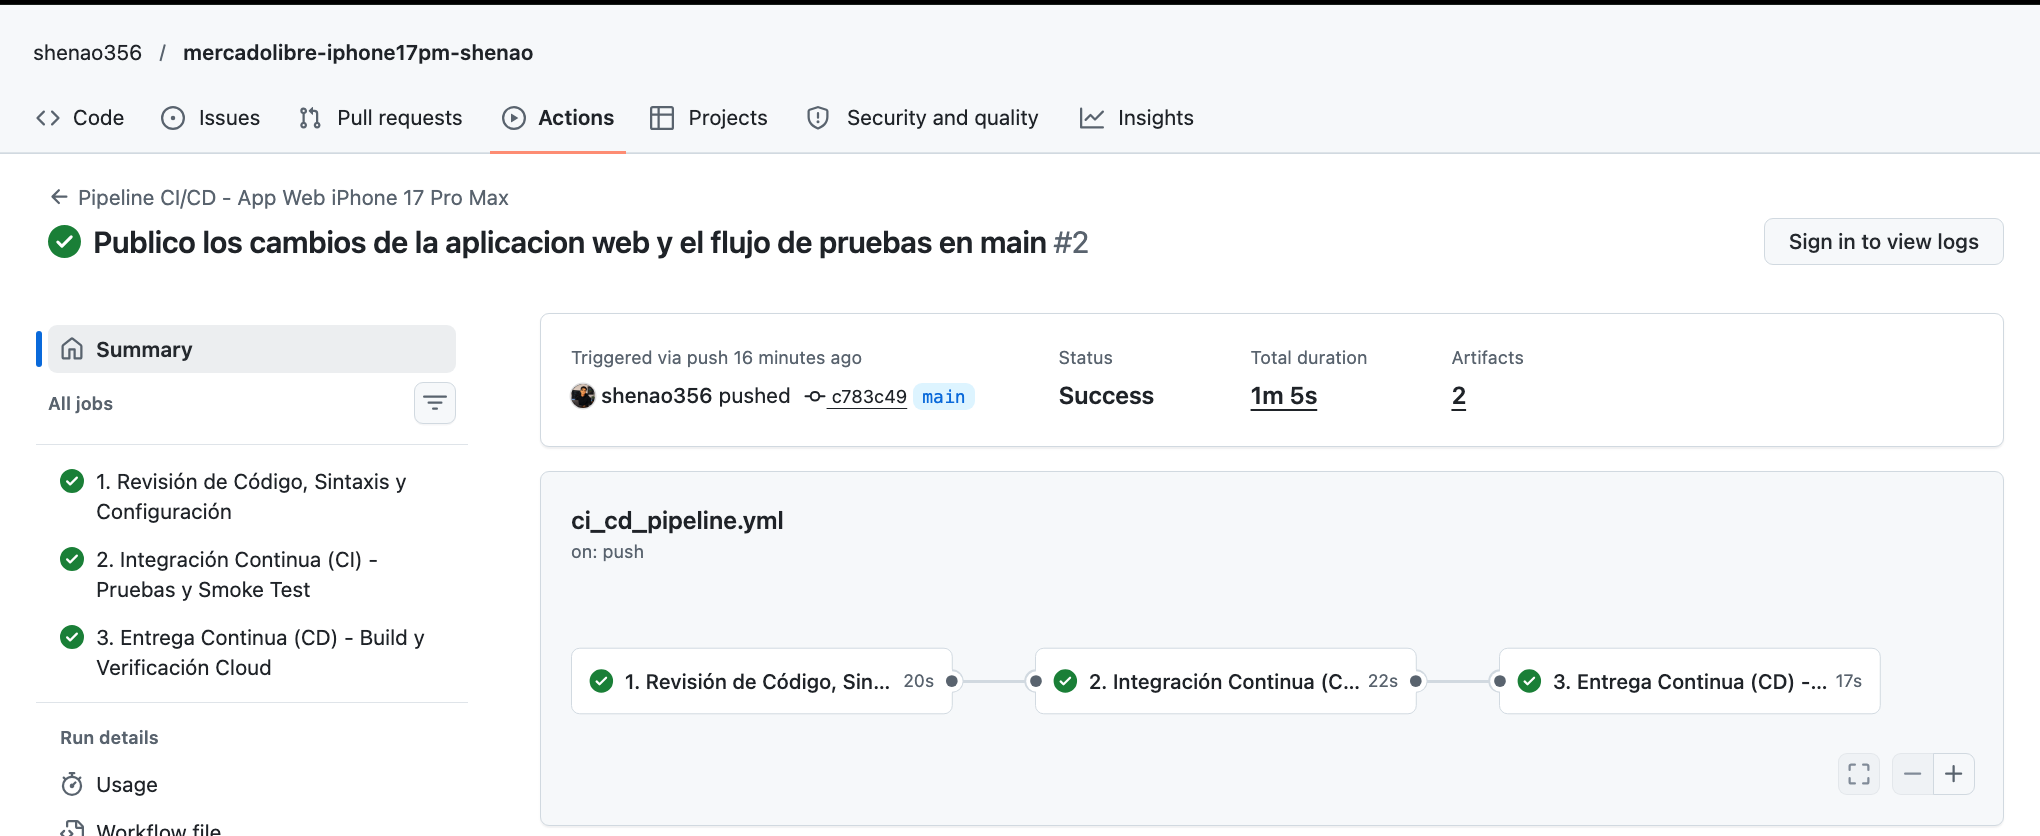

Captura 4: Historial de workflows exitosos en GitHub Actions (Pipeline CI/CD y GitHub Pages)


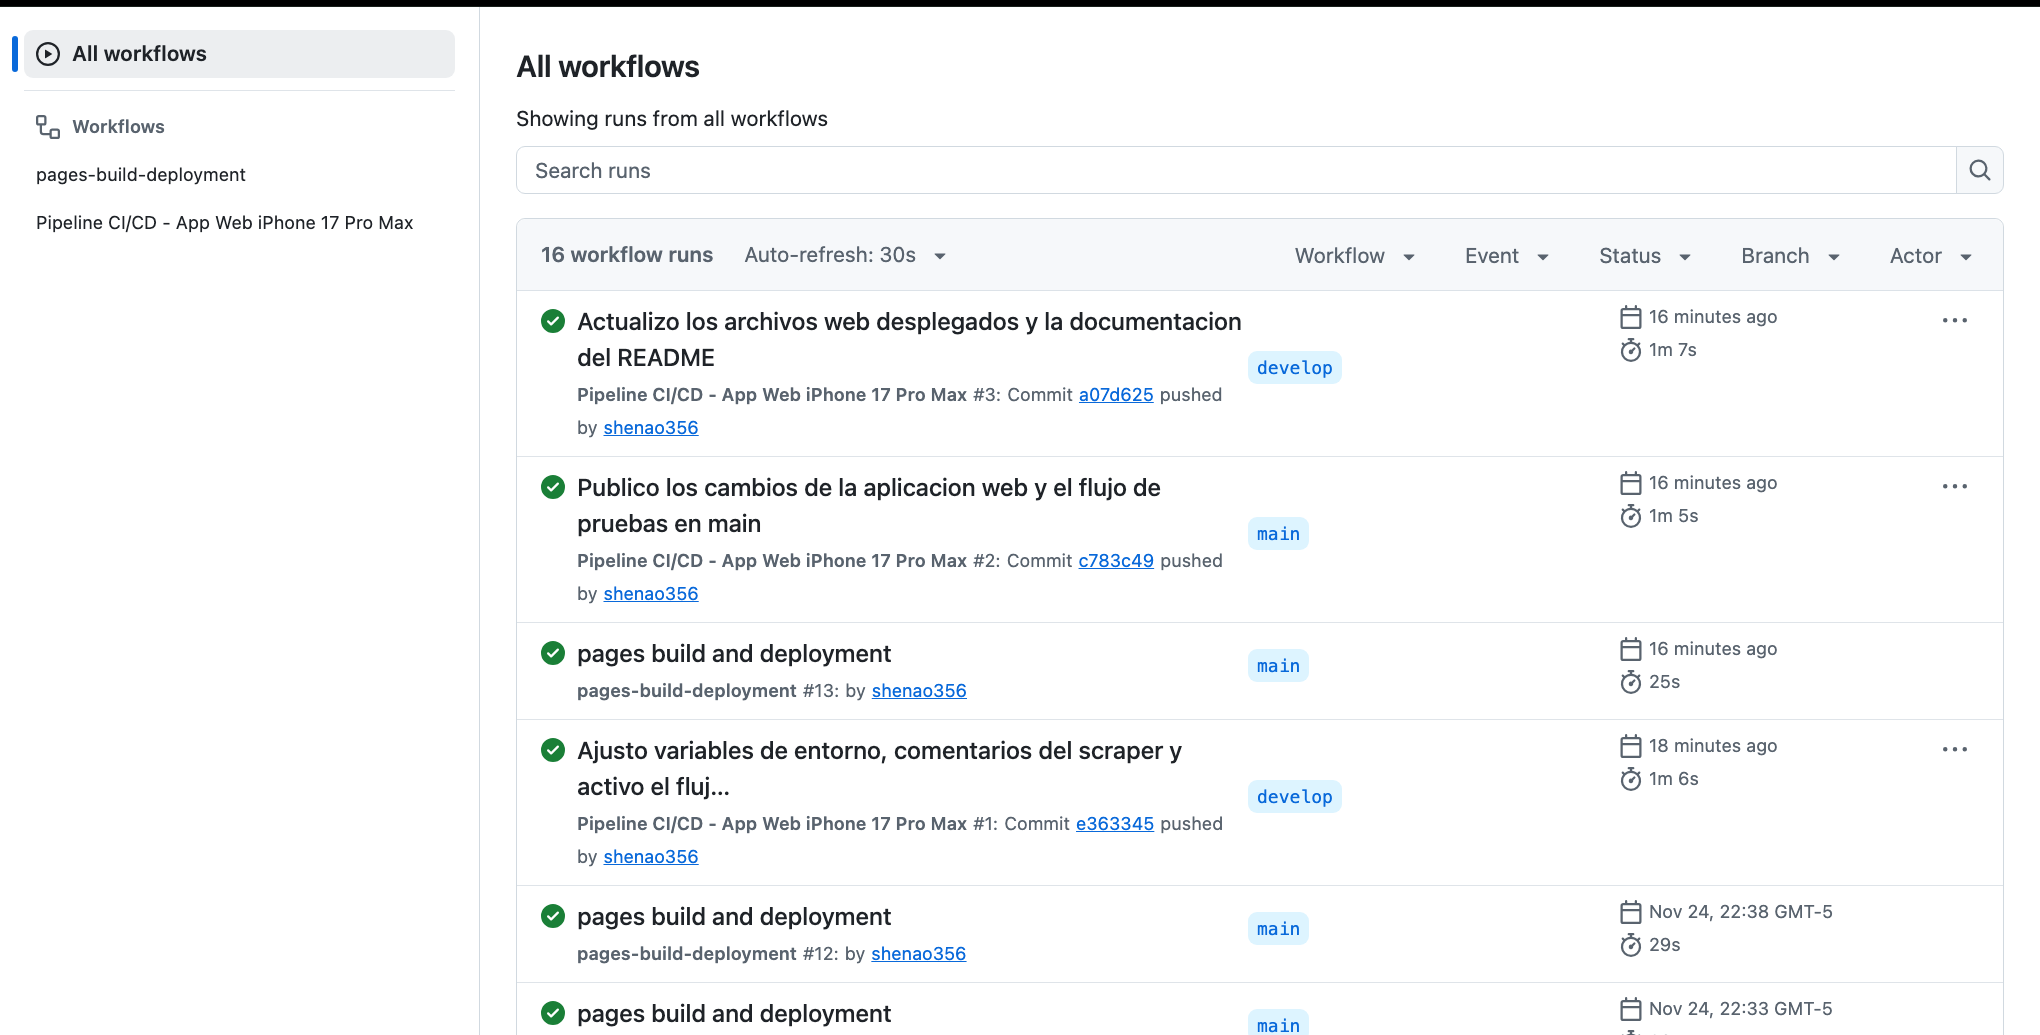

In [7]:
from IPython.display import Image, display

print("Captura 3: Ejecución exitosa del pipeline CI/CD de 3 etapas en GitHub Actions (#2 en main)")
display(Image(filename="docs/screenshots/03b_github_actions_pipeline.png"))

print("Captura 4: Historial de workflows exitosos en GitHub Actions (Pipeline CI/CD y GitHub Pages)")
display(Image(filename="docs/screenshots/03_github_actions_runs.png"))

---
## 8. Conclusiones y Bibliografía (Normas APA 7.ª Edición)

### Conclusiones
1. **Automatización CI/CD activa y verificable:** El flujo `.github/workflows/ci_cd_pipeline.yml` ejecutó en verde sus 3 etapas (`lint-and-syntax`, `ci-automated-tests` y `cd-build-and-verify`) sobre `develop` y `main`, respaldado por 14 pruebas automatizadas (`OK` en `0,535 s`) y generación de 2 artefactos de CI/CD.
2. **Despliegue continuo real y portable:** La aplicación web v3.0.0 y sus endpoints JSON operan en **GitHub Pages** (`HTTP 200`, `pages build and deployment` #13), complementados por `.env.example`, `Dockerfile` y `render.yaml` para portabilidad cloud.
3. **Coherencia analítica:** Las 48 publicaciones del **Apple iPhone 17 Pro Max** registran media de **$ 4.776.156 COP** y mediana de **$ 4.600.000 COP**, concentrando el 72,9 % de la oferta en 256 GB (promedio $ 4.589.380 COP).

### Bibliografía
* Apple Inc. (2026). *iPhone: Especificaciones técnicas y modelos comerciales*. Apple Latinoamérica. https://www.apple.com/co/iphone/
* Chacon, S., & Straub, B. (2014). *Pro Git* (2nd ed.). Apress. https://git-scm.com/book/es/v2
* Chart.js Contributors. (2024). *Chart.js documentation: Simple yet flexible JavaScript charting for designers & developers* (Version 4.4.3). https://www.chartjs.org/docs/latest/
* Docker Inc. (2026). *Dockerfile reference: Best practices for writing Dockerfiles*. https://docs.docker.com/reference/dockerfile/
* Forsgren, N., Humble, J., & Kim, G. (2018). *Accelerate: The science of lean software and DevOps*. IT Revolution Press.
* GitHub Inc. (2026a). *GitHub Actions documentation: Automate your workflow from idea to production*. https://docs.github.com/es/actions
* GitHub Inc. (2026b). *GitHub Pages documentation: Configuring a publishing source for your GitHub Pages site*. https://docs.github.com/es/pages
* Humble, J., & Farley, D. (2010). *Continuous delivery: Reliable software releases through build, test, and deployment automation*. Addison-Wesley Professional.
* Kim, G., Humble, J., Debois, P., Willis, J., & Forsgren, N. (2021). *The DevOps handbook* (2nd ed.). IT Revolution Press.
* Mercado Libre Colombia. (2026). *Catálogo de publicaciones electrónicas: Apple iPhone 17 Pro Max*. https://listado.mercadolibre.com.co/iphone-17-pro-max
* Mitchell, R. (2018). *Web scraping with Python* (2nd ed.). O'Reilly Media.
* Python Software Foundation. (2026). *unittest — Unit testing framework & wsgiref — WSGI utilities and reference implementation* (Python 3.12 Documentation). https://docs.python.org/3/library/
* Richardson, L. (2023). *Beautiful Soup documentation*. Crummy Software. https://www.crummy.com/software/BeautifulSoup/bs4/doc/